In [1]:
# Reloads modules before code execution
# Data is loaded by @src/ so if changed want notebook to reload
%load_ext autoreload
%autoreload 2

In [2]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from super_store.data import load

# Data Exploration
df = load()
print("Head\n", df.head())
# info() prints its own report and returns None, so call it directly
print("Overview")
df.info()
print("Statistics\n", df.describe())

Head
           Category         City        Country Customer ID     Customer Name  \
0  Office Supplies  Los Angeles  United States   LS-172304  Lycoris Saunders   
1  Office Supplies  Los Angeles  United States   MV-174854     Mark Van Huff   
2  Office Supplies  Los Angeles  United States   CS-121304      Chad Sievert   
3  Office Supplies  Los Angeles  United States   CS-121304      Chad Sievert   
4  Office Supplies  Los Angeles  United States   AP-109154    Arthur Prichep   

   Discount Market  ji_lu-shu        Order ID Order Priority  ... Sales  \
0       0.0     US          1  CA-2011-130813           High  ...    19   
1       0.0     US          1  CA-2011-148614         Medium  ...    19   
2       0.0     US          1  CA-2011-118962         Medium  ...    21   
3       0.0     US          1  CA-2011-118962         Medium  ...   111   
4       0.0     US          1  CA-2011-146969           High  ...     6   

    Segment       Ship Mode  Shipping Cost       State  Sub-Ca

In [4]:
# Data Cleaning

# Row ID is unique per row, so ignore it when looking for duplicates
dup_cols = df.columns.drop('Row ID')
print("Duplicate rows:", df.duplicated(subset=dup_cols).sum())
df = df.drop_duplicates(subset=dup_cols, ignore_index=True)

print("Missing values:", df.isna().sum().sum())

# ji_lu-shu ("record count") is 1 on every row, so it carries no information
df = df.drop(columns='ji_lu-shu')

Duplicate rows: 0
Missing values: 0


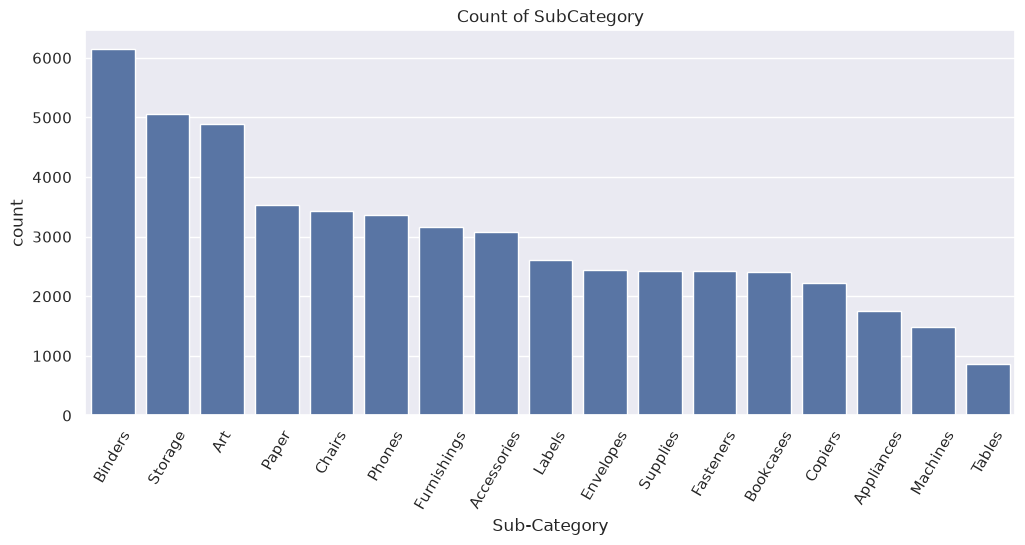

In [5]:
sns.set_theme(rc={'figure.figsize':(12,5)})
order = df['Sub-Category'].value_counts().index
sns.countplot(data=df, x='Sub-Category', order=order)
plt.xticks(rotation=60)
plt.title('Count of SubCategory')
plt.show()

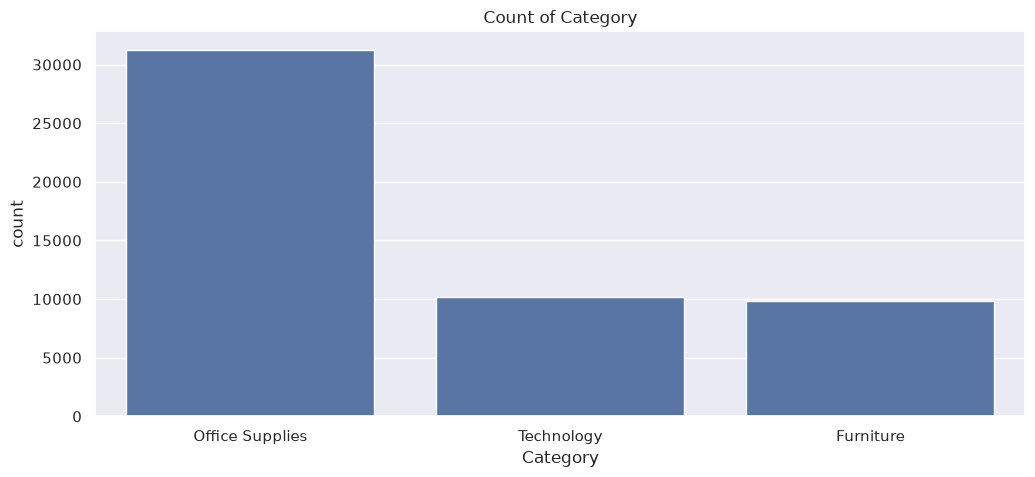

In [6]:
sns.countplot(x='Category', data=df)
plt.title('Count of Category')
plt.show()

In [7]:
df2 = pd.DataFrame(df.groupby('Segment').Profit.mean())
df2

,Profit
Segment,
Consumer,28.254008
Corporate,28.596042
Home Office,29.648847


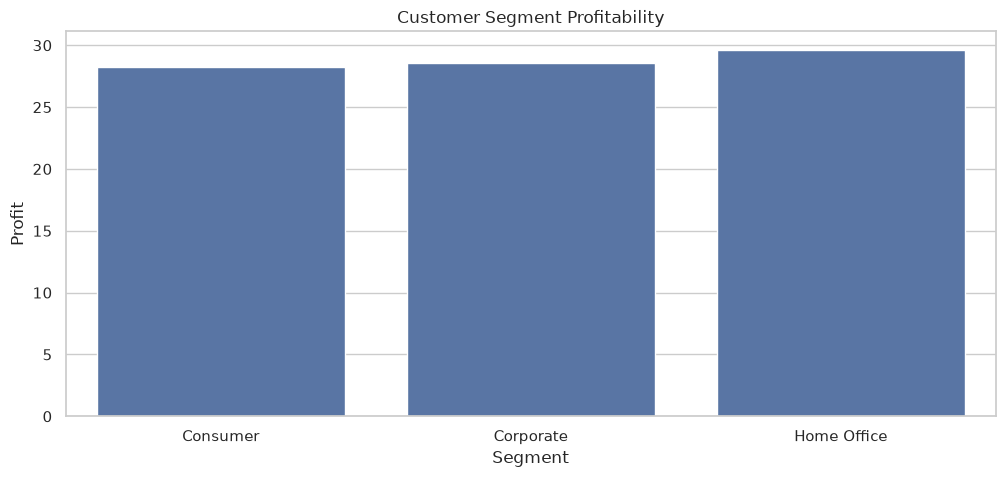

In [8]:
sns.set_theme(style="whitegrid")
sns.barplot(data = df2, x = df2.index, y = df2['Profit'])
plt.title("Customer Segment Profitability")
plt.show()

In [9]:
region_analysis = pd.DataFrame(df.groupby(['Region'])['Profit'].sum().reset_index())
region_analysis

,Region,Profit
0,Africa,88871.63100
1,Canada,17817.39000
2,Caribbean,34571.32104
3,Central,311403.98164
4,Central Asia,132480.18700
5,EMEA,43897.97100
6,East,91522.78000
7,North,194597.95252
8,North Asia,165578.42100
9,Oceania,120089.11200


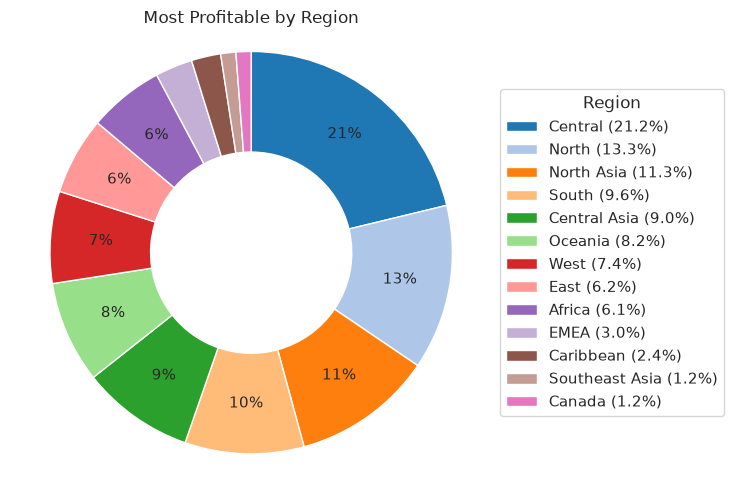

In [10]:
# Sort so slices run largest to smallest clockwise from the top
pie_data = region_analysis.sort_values('Profit', ascending=False)
shares = pie_data.Profit / pie_data.Profit.sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 5))
wedges, texts, autotexts = ax.pie(
    pie_data.Profit,
    startangle=90,
    counterclock=False,
    colors=sns.color_palette('tab20', len(pie_data)),
    # Hide labels on tiny slices; the legend shows every region's share
    autopct=lambda pct: f'{pct:.0f}%' if pct >= 3 else '',
    pctdistance=0.75,
    wedgeprops=dict(width=0.5, edgecolor='white'),
    textprops=dict(fontsize=11),
)

ax.legend(wedges, [f'{r} ({s:.1f}%)' for r, s in zip(pie_data.Region, shares)],
          title='Region', loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_title('Most Profitable by Region')
ax.axis('equal')
plt.tight_layout()
plt.show()

In [11]:
# RFM Analysis
# Customer ID is per market (same person has a different ID in each market),
# so each ID is treated as its own customer. Recency is week-accurate because
# Order Week is the only order date available.
snapshot = df['Order Week'].max() + pd.Timedelta(days=7)

rfm = df.groupby('Customer ID').agg(
    Recency=('Order Week', lambda d: (snapshot - d.max()).days),
    Frequency=('Order ID', 'nunique'),
    Monetary=('Sales', 'sum'),
)
rfm.describe()

,Recency,Frequency,Monetary
count,4873.000000,4873.000000,4873.000000
mean,213.822902,5.284835,2594.480813
std,254.723185,2.857330,2465.921576
min,7.000000,1.000000,2.000000
25%,49.000000,3.000000,728.000000
50%,119.000000,5.000000,1894.000000
75%,273.000000,7.000000,3763.000000
max,1460.000000,18.000000,25042.000000


In [12]:
# Score each metric 1-5 by quintile (5 = best). Ranking first breaks ties so
# qcut can always form 5 equal-sized bins.
rfm['R'] = pd.qcut(rfm.Recency.rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm.Frequency.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M'] = pd.qcut(rfm.Monetary.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Standard segment map on the R and F scores
segment_map = {
    r'[1-2][1-2]': 'Hibernating',
    r'[1-2][3-4]': 'At Risk',
    r'[1-2]5': "Can't Lose",
    r'3[1-2]': 'About to Sleep',
    r'33': 'Need Attention',
    r'[3-4][4-5]': 'Loyal Customers',
    r'41': 'Promising',
    r'51': 'New Customers',
    r'[4-5][2-3]': 'Potential Loyalists',
    r'5[4-5]': 'Champions',
}
rfm['Segment'] = (rfm.R.astype(str) + rfm.F.astype(str)).replace(segment_map, regex=True)
rfm.head()

,Recency,Frequency,Monetary,R,F,M,Segment
Customer ID,,,,,,,
AA-103151,14,5,1445,5,3,3,Potential Loyalists
AA-103152,21,7,6105,5,4,5,Champions
AA-103153,701,2,633,1,1,2,Hibernating
AA-103154,189,5,5565,2,3,5,At Risk
AA-103751,14,4,2407,5,2,3,Potential Loyalists


In [13]:
segment_summary = rfm.groupby('Segment').agg(
    Customers=('Segment', 'size'),
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary=('Monetary', 'mean'),
    Sales=('Monetary', 'sum'),
)
segment_summary['% Customers'] = segment_summary.Customers / segment_summary.Customers.sum() * 100
segment_summary['% Sales'] = segment_summary.Sales / segment_summary.Sales.sum() * 100
segment_summary = segment_summary.sort_values('Sales', ascending=False)
segment_summary.round(1)

,Customers,Recency,Frequency,Monetary,Sales,% Customers,% Sales
Segment,,,,,,,
Loyal Customers,980,84.2,8.1,4289.4,4203568,20.1,33.2
Champions,572,22.0,8.5,4258.6,2435906,11.7,19.3
At Risk,590,319.3,5.6,2855.9,1684998,12.1,13.3
Potential Loyalists,698,40.6,4.5,2079.0,1451123,14.3,11.5
Hibernating,1208,516.2,2.3,909.3,1098448,24.8,8.7
Can't Lose,151,249.8,9.3,4804.7,725508,3.1,5.7
Need Attention,222,117.0,5.0,2637.5,585527,4.6,4.6
About to Sleep,297,121.5,2.9,1204.8,357835,6.1,2.8
Promising,88,58.5,1.9,620.5,54606,1.8,0.4


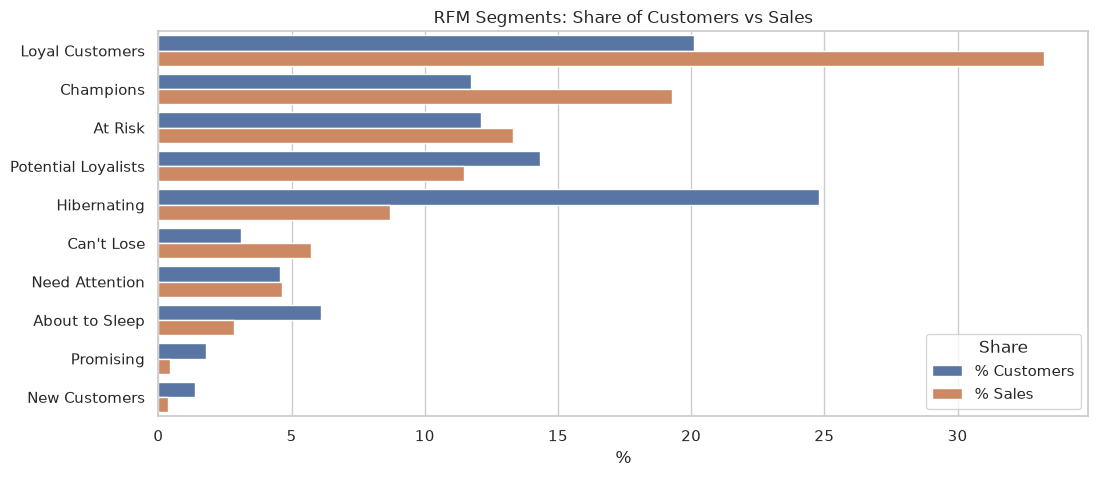

In [14]:
# Compare each segment's share of customers with its share of sales
shares = segment_summary[['% Customers', '% Sales']].reset_index().melt(
    id_vars='Segment', var_name='Share', value_name='Percent')

sns.barplot(data=shares, y='Segment', x='Percent', hue='Share')
plt.title('RFM Segments: Share of Customers vs Sales')
plt.xlabel('%')
plt.ylabel('')
plt.show()

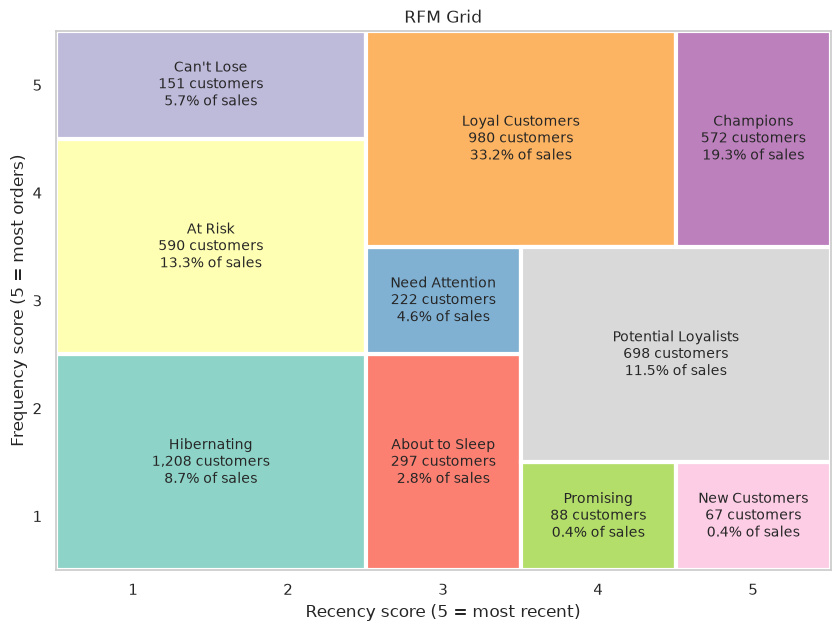

In [15]:
# RFM Grid: each segment's block on the Recency x Frequency score grid
# (R from, R to, F from, F to), matching segment_map above
segment_blocks = {
    'Hibernating': (1, 2, 1, 2),
    'At Risk': (1, 2, 3, 4),
    "Can't Lose": (1, 2, 5, 5),
    'About to Sleep': (3, 3, 1, 2),
    'Need Attention': (3, 3, 3, 3),
    'Loyal Customers': (3, 4, 4, 5),
    'Promising': (4, 4, 1, 1),
    'New Customers': (5, 5, 1, 1),
    'Potential Loyalists': (4, 5, 2, 3),
    'Champions': (5, 5, 4, 5),
}
colors = dict(zip(segment_blocks, sns.color_palette('Set3', len(segment_blocks))))

fig, ax = plt.subplots(figsize=(10, 7))
for segment, (r0, r1, f0, f1) in segment_blocks.items():
    ax.add_patch(plt.Rectangle((r0 - 0.5, f0 - 0.5), r1 - r0 + 1, f1 - f0 + 1,
                               facecolor=colors[segment], edgecolor='white', linewidth=3))
    row = segment_summary.loc[segment]
    ax.text((r0 + r1) / 2, (f0 + f1) / 2,
            f"{segment}\n{row.Customers:,.0f} customers\n{row['% Sales']:.1f}% of sales",
            ha='center', va='center', fontsize=10)

ax.set_xlim(0.5, 5.5)
ax.set_ylim(0.5, 5.5)
ax.set_xticks(range(1, 6))
ax.set_yticks(range(1, 6))
ax.grid(False)
ax.set_xlabel('Recency score (5 = most recent)')
ax.set_ylabel('Frequency score (5 = most orders)')
ax.set_title('RFM Grid')
plt.show()